In [5]:
# CELLULE 1 : Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl          # ← AJOUTE CETTE LIGNE
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

# Configuration
pd.options.display.max_rows = 40
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
mpl.rcParams['figure.figsize'] = (12.0, 6.0)

In [6]:
# CELLULE 2 : Charger les données

games = pd.read_csv('../data/games.csv')
clubs = pd.read_csv('../data/clubs.csv')
elo = pd.read_csv('../data/EloRatings.csv')
players = pd.read_csv('../data/players.csv')

print("✅ Données chargées!")

✅ Données chargées!


In [7]:
pd.set_option("display.max_rows", None)      # afficher toutes les lignes
pd.set_option("display.max_columns", None)   # afficher toutes les colonnes
 
df = pd.read_csv("../data/games.csv")
 
cl = df[df["competition_id"] == "CL"].sort_values("date")
 
cl[["game_id", "date", "season", "round", "home_club_name", "away_club_name", "home_club_goals", "away_club_goals"]]

,game_id,date,season,round,home_club_name,away_club_name,home_club_goals,away_club_goals
4483,2262147,2012-09-18,2012,Group A,GNK Dinamo Zagreb,FC Porto,0,2
4484,2262148,2012-09-18,2012,Group A,Paris Saint-Germain,Dynamo Kyiv,4,1
4485,2262149,2012-09-18,2012,Group B,Montpellier HSC,Arsenal FC,1,2
4486,2262150,2012-09-18,2012,Group B,Olympiakos Syndesmos Filathlon Peiraios,FC Schalke 04,1,2
4487,2262151,2012-09-18,2012,Group C,Málaga CF,AO FK Zenit Sankt-Peterburg,3,0
4488,2262152,2012-09-18,2012,Group C,AC Milan,RSC Anderlecht,0,0
4489,2262153,2012-09-18,2012,Group D,Real Madrid,Manchester City,3,2
4490,2262154,2012-09-18,2012,Group D,Borussia Dortmund,Ajax Amsterdam,1,0
4498,2262162,2012-09-19,2012,Group H,SC Braga,CFR Cluj,0,2
4497,2262161,2012-09-19,2012,Group H,Manchester United,Galatasaray,1,0


In [8]:
import os
print("Répertoire courant:", os.getcwd())
print("\nFichiers disponibles:")
print(os.listdir('.'))

Répertoire courant: C:\Users\loan0\Documents\Projet-datascience\CHAMPIONS-\analyse

Fichiers disponibles:
['.gitkeep', '.ipynb_checkpoints', 'eda_champions_league.ipynb.ipynb']


In [9]:
# CELLULE 3 : Explorer la structure
print("📊 GAMES.CSV")
print(f"Shape: {games.shape}")
print(f"Colonnes: {list(games.columns)[:8]}...")
print("\nPremières lignes:")
print(games.head(10))

📊 GAMES.CSV
Shape: (88958, 23)
Colonnes: ['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals']...

Premières lignes:
   game_id competition_id  season           round        date  home_club_id  \
0  1026846           FIWC    2009     Round of 16  2010-06-26          3449   
1  1026847           FIWC    2009     Round of 16  2010-06-27          3437   
2  1027001           FIWC    2009     Round of 16  2010-06-26          3505   
3  1027002           FIWC    2009     Round of 16  2010-06-27          3262   
4  1027048           FIWC    2009     Round of 16  2010-06-28          3379   
5  1027049           FIWC    2009     Round of 16  2010-06-29          3581   
6  1027635           FIWC    2009     Round of 16  2010-06-28          3439   
7  1027636           FIWC    2009     Round of 16  2010-06-29          3375   
8  1027723           FIWC    2009  Quarter-Finals  2010-07-02          3449   
9  1027750           FIWC    2009  Quar

In [10]:
# CELLULE 4 : Types de données
print("\n🔍 Types de données:")
print(games.dtypes)


🔍 Types de données:
game_id                     int64
competition_id             object
season                      int64
round                      object
date                       object
home_club_id                int64
away_club_id                int64
home_club_goals             int64
away_club_goals             int64
home_club_position        float64
away_club_position        float64
home_club_manager_name     object
away_club_manager_name     object
stadium                    object
attendance                float64
referee                    object
url                        object
home_club_formation        object
away_club_formation        object
home_club_name             object
away_club_name             object
aggregate                  object
competition_type           object
dtype: object


In [11]:
# cellule 5Filter for Champions League matches
ucl_games = games[games['competition_id'] == 'CL'].copy()

print(f"✅ Champions League matches: {len(ucl_games):,}")
print(f"\n📅 Seasons in dataset: {sorted(ucl_games['season'].unique())}")
print(f"\n📊 Matches per season:")
print(ucl_games['season'].value_counts().sort_index())

✅ Champions League matches: 1,871

📅 Seasons in dataset: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

📊 Matches per season:
season
2012    125
2013    125
2014    125
2015    125
2016    125
2017    125
2018    125
2019    119
2020    125
2021    125
2022    125
2023    125
2024    189
2025    188
Name: count, dtype: int64


In [12]:
# CELLULE 6 : Nettoyage - Supprimer les NaN
games_clean = games.dropna()
print(f"Avant: {len(games)} lignes")
print(f"Après: {len(games_clean)} lignes")

Avant: 88958 lignes
Après: 52344 lignes


In [13]:
# CELLULE 7 : Statistiques descriptives
print("\n📈 STATISTIQUES:")
print(games_clean[['home_club_goals', 'away_club_goals', 'season']].describe())

# Voir les noms des colonnes
print("Colonnes disponibles dans games:")
print(games.columns.tolist())

print("\nPremières lignes:")
print(games.head(3))


📈 STATISTIQUES:
       home_club_goals  away_club_goals        season
count     52344.000000     52344.000000  52344.000000
mean          1.536585         1.206939   2019.502751
std           1.302850         1.162120      4.096713
min           0.000000         0.000000   2013.000000
25%           1.000000         0.000000   2016.000000
50%           1.000000         1.000000   2019.000000
75%           2.000000         2.000000   2024.000000
max          10.000000         9.000000   2025.000000
Colonnes disponibles dans games:
['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'home_club_manager_name', 'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url', 'home_club_formation', 'away_club_formation', 'home_club_name', 'away_club_name', 'aggregate', 'competition_type']

Premières lignes:
   game_id competition_id  season        round        date  home

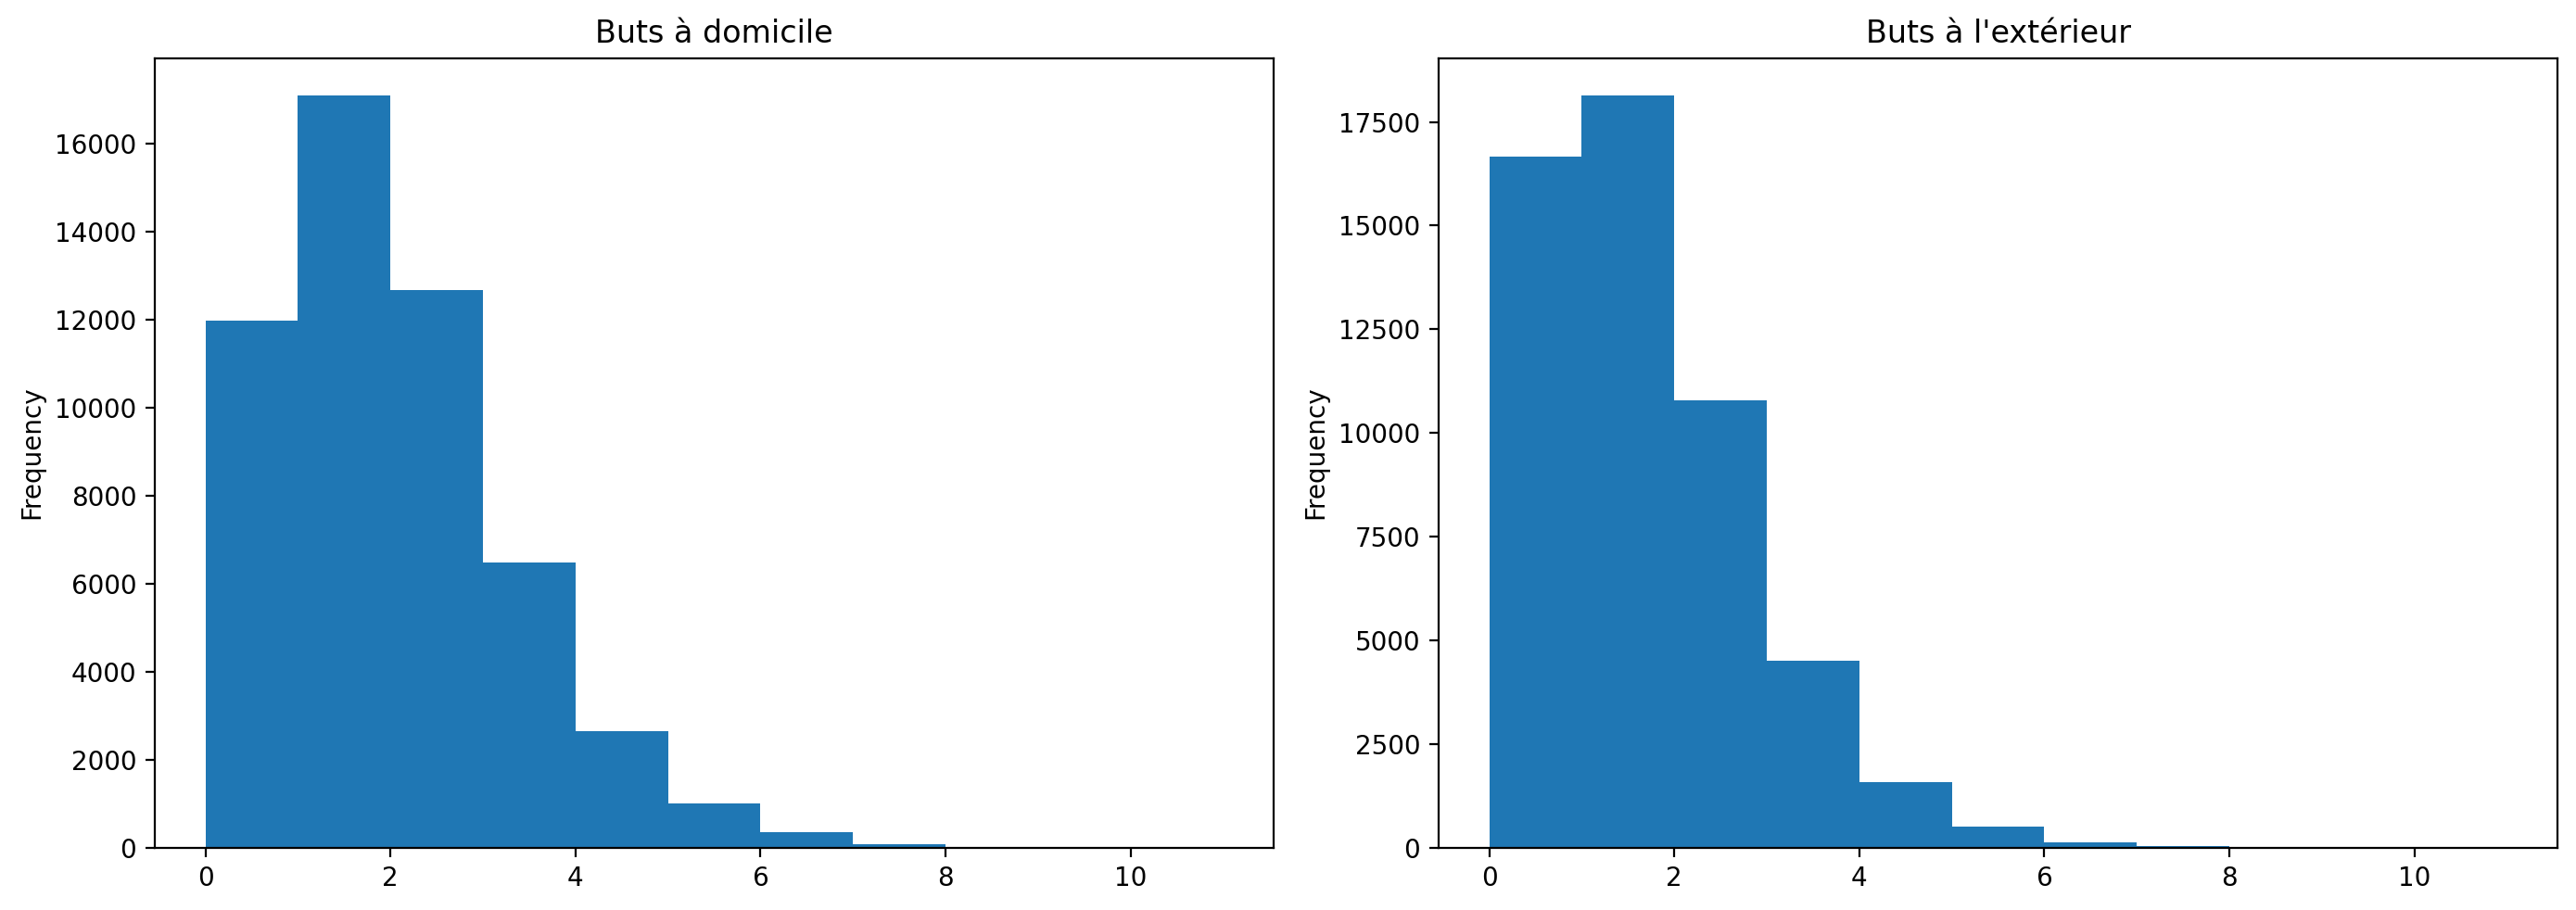

In [14]:
# CELLULE 8 : Distribution des buts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bins = np.arange(0, 12)
games_clean['home_club_goals'].plot(kind='hist', bins=bins, ax=ax1, title='Buts à domicile')
games_clean['away_club_goals'].plot(kind='hist', bins=bins, ax=ax2, title='Buts à l\'extérieur')
plt.tight_layout()
plt.show()

In [15]:
print("\n📊 Descriptive Statistics - Champions League Goals:")
print(ucl_games[['home_club_goals', 'away_club_goals', 'season']].describe())

print("\n⚽ Goal Statistics:")
print(f"  Home team avg goals: {ucl_games['home_club_goals'].mean():.2f}")
print(f"  Away team avg goals: {ucl_games['away_club_goals'].mean():.2f}")
print(f"  Total goals per match: {(ucl_games['home_club_goals'] + ucl_games['away_club_goals']).mean():.2f}")


📊 Descriptive Statistics - Champions League Goals:
       home_club_goals  away_club_goals       season
count      1871.000000      1871.000000  1871.000000
mean          1.738642         1.356494  2018.905398
std           1.488853         1.340688     4.183380
min           0.000000         0.000000  2012.000000
25%           1.000000         0.000000  2015.000000
50%           1.000000         1.000000  2019.000000
75%           3.000000         2.000000  2023.000000
max           9.000000         8.000000  2025.000000

⚽ Goal Statistics:
  Home team avg goals: 1.74
  Away team avg goals: 1.36
  Total goals per match: 3.10


In [16]:
# CELLULE 9 : Filter Champions League
print("\n📊 Descriptive Statistics - Champions League Goals:")
print(ucl_games[['home_club_goals', 'away_club_goals', 'season']].describe())

print("\n⚽ Goal Statistics:")
print(f"  Home team avg goals: {ucl_games['home_club_goals'].mean():.2f}")
print(f"  Away team avg goals: {ucl_games['away_club_goals'].mean():.2f}")
print(f"  Total goals per match: {(ucl_games['home_club_goals'] + ucl_games['away_club_goals']).mean():.2f}")


📊 Descriptive Statistics - Champions League Goals:
       home_club_goals  away_club_goals       season
count      1871.000000      1871.000000  1871.000000
mean          1.738642         1.356494  2018.905398
std           1.488853         1.340688     4.183380
min           0.000000         0.000000  2012.000000
25%           1.000000         0.000000  2015.000000
50%           1.000000         1.000000  2019.000000
75%           3.000000         2.000000  2023.000000
max           9.000000         8.000000  2025.000000

⚽ Goal Statistics:
  Home team avg goals: 1.74
  Away team avg goals: 1.36
  Total goals per match: 3.10


In [17]:
# CELLULE 10 : Top teams
print("\n⭐ TOP 10 TEAMS (historique):")
home_wins = ucl_games[ucl_games['home_club_goals'] > ucl_games['away_club_goals']]['home_club_name'].value_counts()
away_wins = ucl_games[ucl_games['away_club_goals'] > ucl_games['home_club_goals']]['away_club_name'].value_counts()
total_wins = home_wins.add(away_wins, fill_value=0).sort_values(ascending=False)

for i, (team, wins) in enumerate(total_wins.head(10).items(), 1):
    print(f"  {i:2d}. {team:30s} - {int(wins)} victoires")


⭐ TOP 10 TEAMS (historique):
   1. Real Madrid                    - 112 victoires
   2. Bayern Munich                  - 111 victoires
   3. FC Barcelona                   - 85 victoires
   4. Paris Saint-Germain            - 84 victoires
   5. Manchester City                - 77 victoires
   6. Atlético de Madrid             - 65 victoires
   7. Juventus FC                    - 61 victoires
   8. Borussia Dortmund              - 60 victoires
   9. Liverpool FC                   - 56 victoires
  10. Chelsea FC                     - 49 victoires


In [18]:
# CELLULE 11 : Corrélation et Elo ratings
print("\n⭐ MEILLEURS CLUBS (par Elo rating):")
top_elo = elo.nlargest(10, 'elo')[['club', 'elo']].drop_duplicates('club')
print(top_elo)


⭐ MEILLEURS CLUBS (par Elo rating):
                 club      elo
115065      Barcelona  2107.48
134066  Bayern Munich  2101.50
135568    Real Madrid  2098.62


In [19]:
# Vérifier les compétitions disponibles
print("Valeurs de competition_id:")
print(games['competition_id'].unique()[:20])
print(f"\nNombre de matchs par compétition:")
print(games['competition_id'].value_counts())

Valeurs de competition_id:
['FIWC' 'EURO' 'NLSC' 'SCI' 'BESC' 'USC' 'DFB' 'ELQ' 'L1' 'RU1' 'UKR1'
 'FR1' 'DK1' 'BE1' 'GB1' 'SC1' 'DFL' 'CLQ' 'UKRS' 'UKRP']

Nombre de matchs par compétition:
competition_id
ES1     5320
IT1     5320
GB1     5320
FR1     4997
TR1     4618
L1      4284
NL1     4210
PO1     4152
BE1     3550
RU1     3360
GR1     3085
SC1     2903
UKR1    2700
ELQ     2677
EL      2628
DK1     2312
FAC     2014
CL      1871
CDR     1677
RUP     1645
SFA     1364
ECLQ    1344
NLP     1266
CLQ     1232
GRP     1230
DKP     1216
CIT      933
DFB      880
UCOL     728
MLS1     727
UKRP     679
SA1      612
PL1      612
POCP     602
BRA1     557
TS1      480
SER1     480
RO1      480
C1       430
ARG1     418
FIWC     392
A1       356
KR1      348
NO1      329
SE1      329
AUS1     325
JAP1     296
CGB      246
MEX1     241
RSK1     231
EURO     215
COL1     200
KLUB     156
AFCN      52
AFAC      51
SUC       34
COPA      32
EJPL      30
POBE      30
SCI       20
USC       14
D

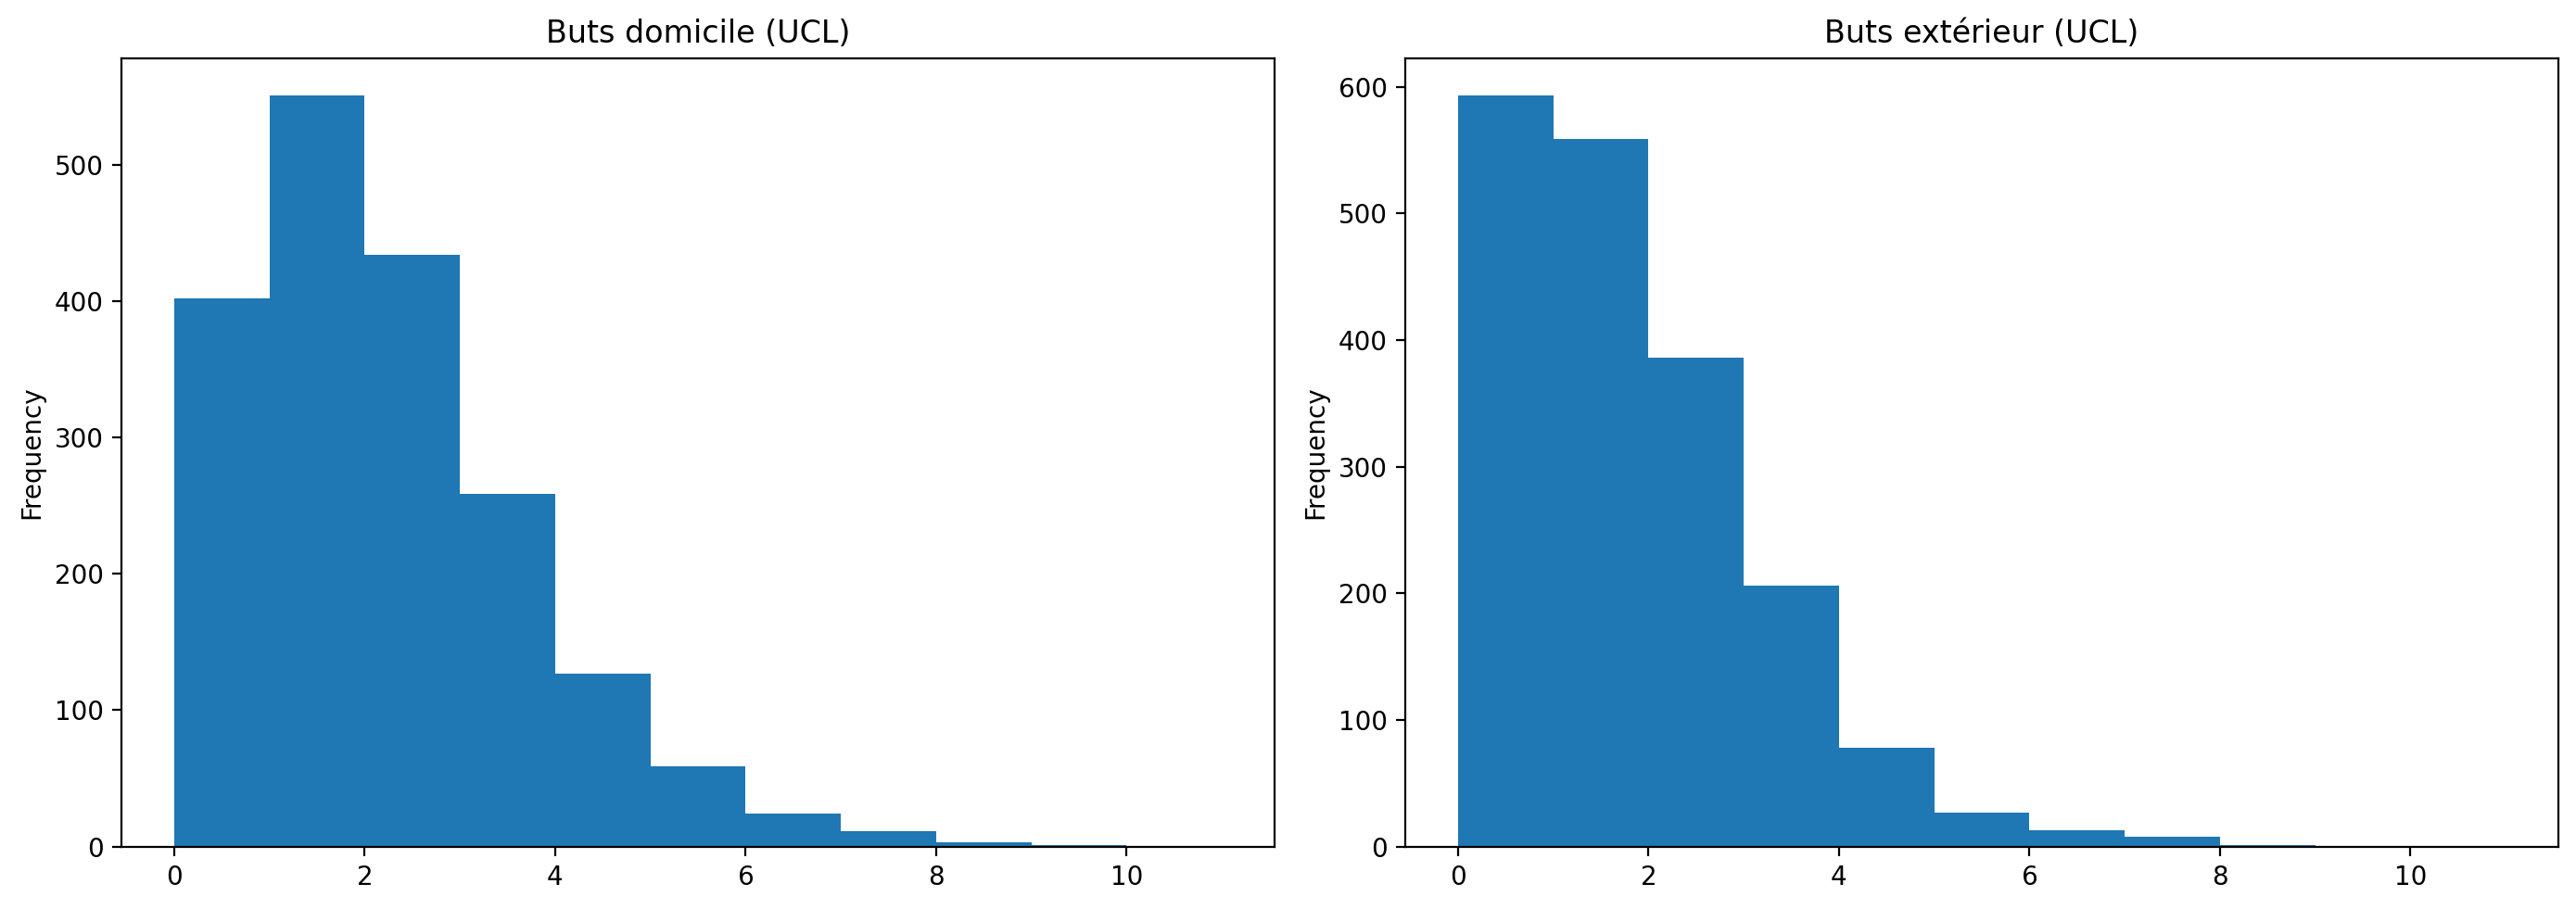

In [20]:
# CELLULE 12 : Distribution des buts UCL
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bins = np.arange(0, 12)

ucl_games['home_club_goals'].plot(kind='hist', bins=bins, ax=ax1, title='Buts domicile (UCL)')
ucl_games['away_club_goals'].plot(kind='hist', bins=bins, ax=ax2, title='Buts extérieur (UCL)')

plt.tight_layout()
plt.show()

In [21]:
# CELLULE 13 : Performance récente (3 dernières saisons)
max_season = ucl_games['season'].max()
min_season = max_season - 2
recent = ucl_games[ucl_games['season'] >= min_season]

print(f"\n🔥 PERFORMANCE RÉCENTE ({min_season} - {max_season}):")
home_wins = recent[recent['home_club_goals'] > recent['away_club_goals']]['home_club_name'].value_counts()
away_wins = recent[recent['away_club_goals'] > recent['home_club_goals']]['away_club_name'].value_counts()
recent_wins = home_wins.add(away_wins, fill_value=0).sort_values(ascending=False)

for i, (team, wins) in enumerate(recent_wins.head(10).items(), 1):
    print(f" {i:2d}. {team:30s} - {int(wins)} victoires")


🔥 PERFORMANCE RÉCENTE (2023 - 2025):
  1. Real Madrid                    - 28 victoires
  2. Bayern Munich                  - 26 victoires
  3. Paris Saint-Germain            - 26 victoires
  4. Arsenal FC                     - 25 victoires
  5. FC Barcelona                   - 22 victoires
  6. Inter Milan                    - 19 victoires
  7. Borussia Dortmund              - 19 victoires
  8. Atlético de Madrid             - 19 victoires
  9. Manchester City                - 16 victoires
 10. Liverpool FC                   - 15 victoires


In [22]:
# CELLULE 14 : Avantage du terrain
print("\n🏟️ AVANTAGE DU TERRAIN (UCL):")
home_avg = ucl_games['home_club_goals'].mean()
away_avg = ucl_games['away_club_goals'].mean()
print(f"Moyenne buts domicile: {home_avg:.2f}")
print(f"Moyenne buts extérieur: {away_avg:.2f}")
print(f"Avantage: +{home_avg - away_avg:.2f} buts")


🏟️ AVANTAGE DU TERRAIN (UCL):
Moyenne buts domicile: 1.74
Moyenne buts extérieur: 1.36
Avantage: +0.38 buts


In [23]:
# CELLULE 15 : Corrélation matrix (si données numériques)
print("\n🔗 CORRÉLATIONS:")
numeric_cols = ucl_games.select_dtypes(include=[np.number]).columns
correlation = ucl_games[numeric_cols].corr()
print(correlation)


🔗 CORRÉLATIONS:
                     game_id    season  home_club_id  away_club_id  \
game_id             1.000000  0.989024      0.059079      0.060041   
season              0.989024  1.000000      0.064112      0.065144   
home_club_id        0.059079  0.064112      1.000000     -0.017154   
away_club_id        0.060041  0.065144     -0.017154      1.000000   
home_club_goals     0.045602  0.040073     -0.040868      0.044033   
away_club_goals     0.056198  0.056073      0.063617     -0.047359   
home_club_position       NaN       NaN           NaN           NaN   
away_club_position       NaN       NaN           NaN           NaN   
attendance          0.037966  0.022958     -0.182577     -0.034218   

                    home_club_goals  away_club_goals  home_club_position  \
game_id                    0.045602         0.056198                 NaN   
season                     0.040073         0.056073                 NaN   
home_club_id              -0.040868         0.063617  

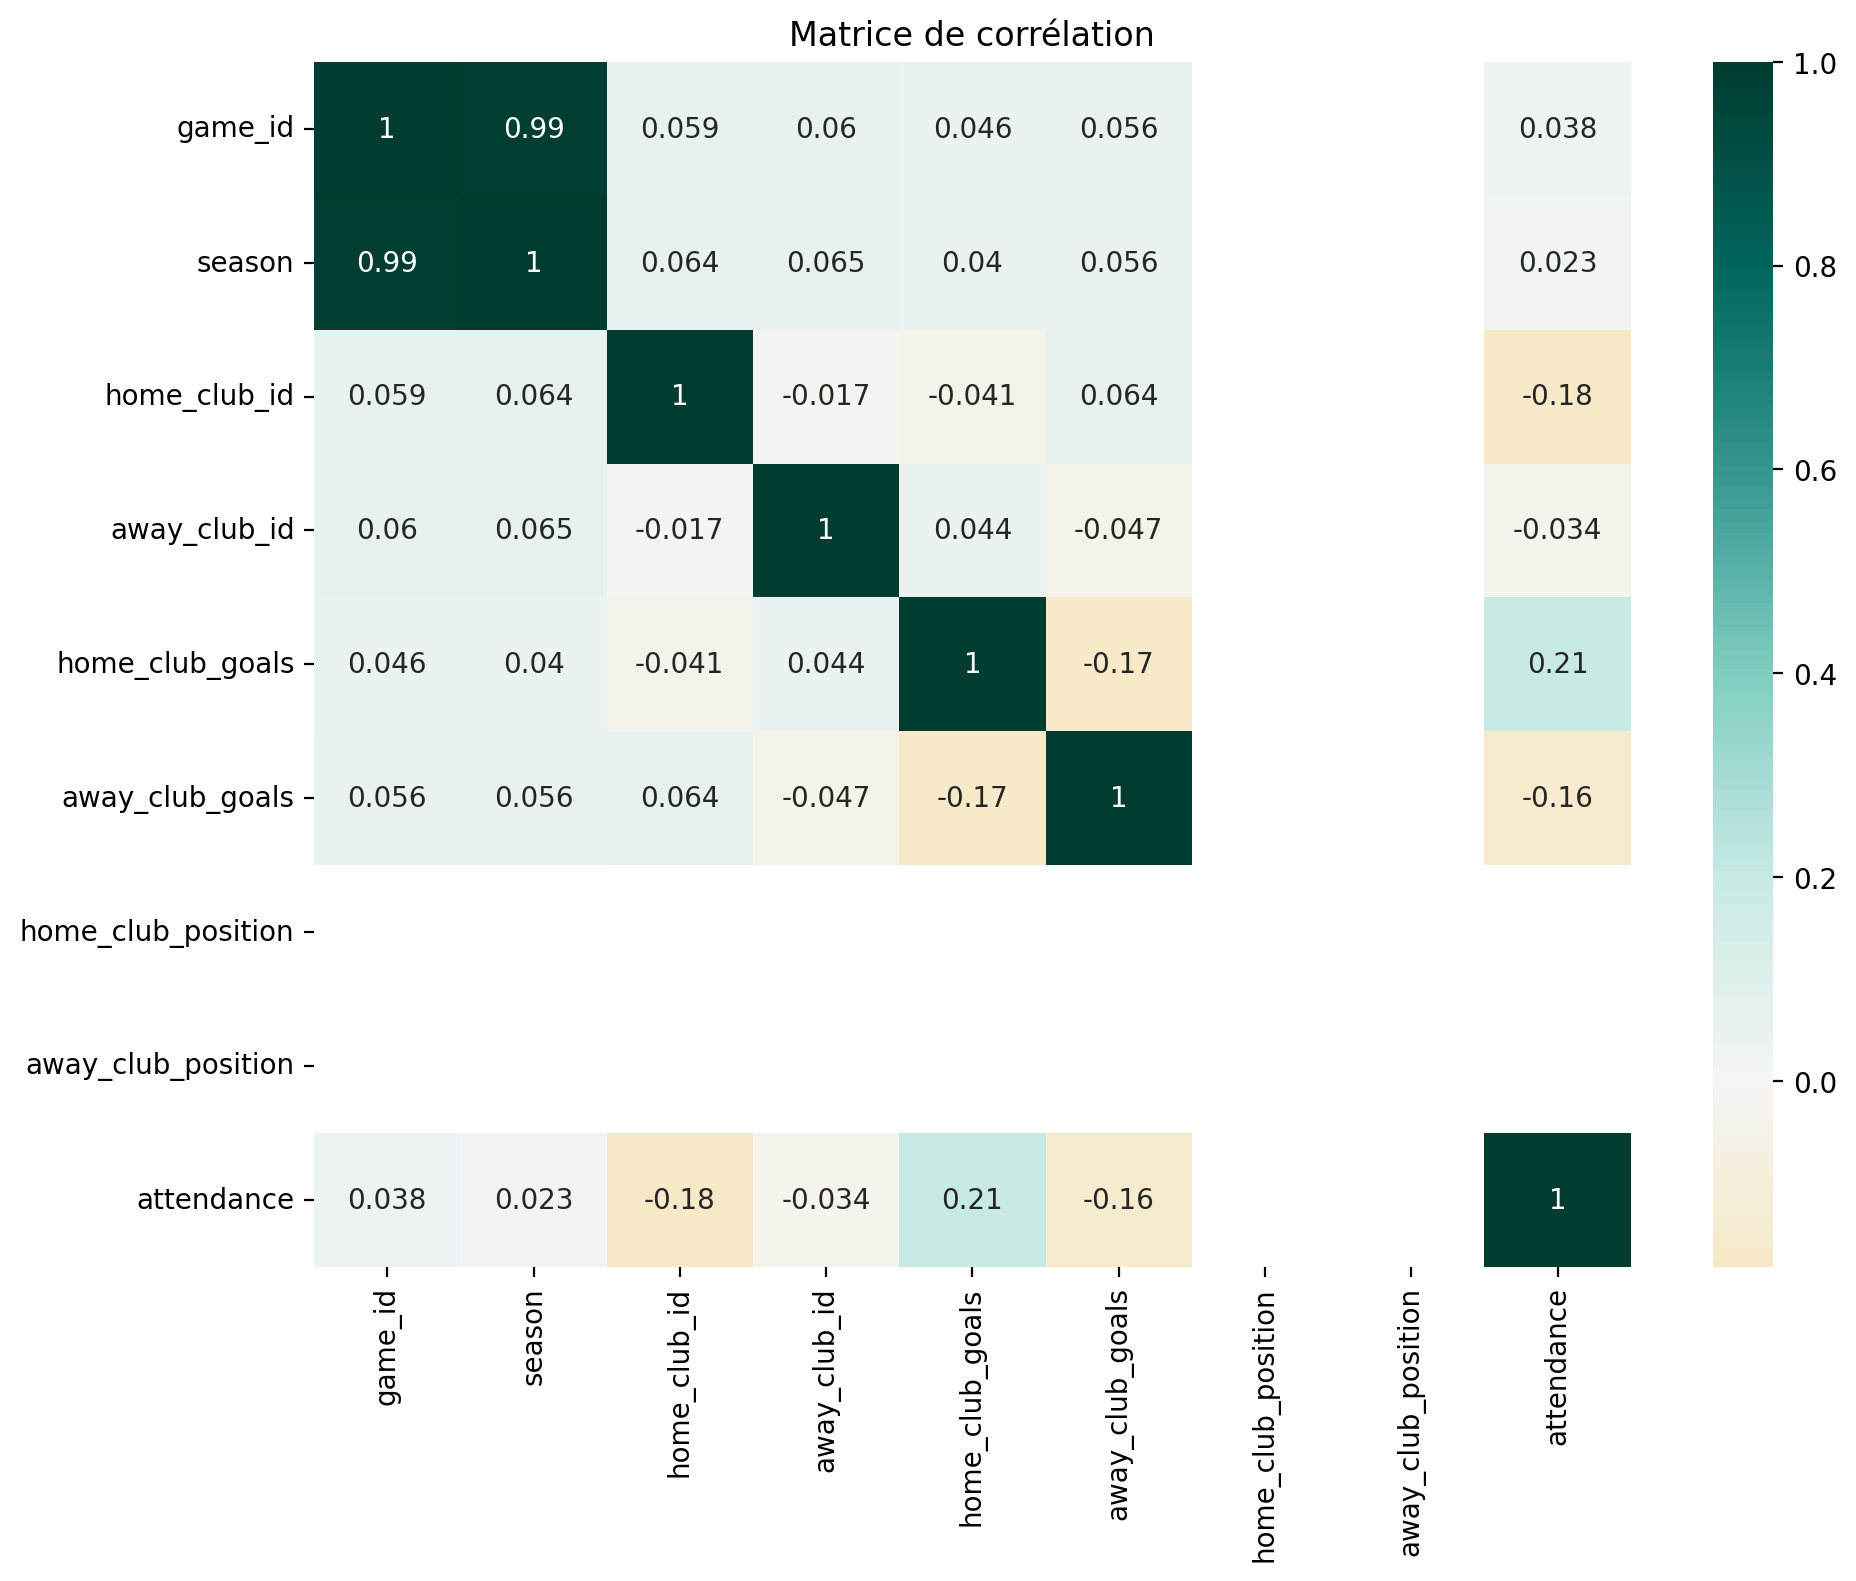

In [24]:
# CELLULE 16: Heatmap - CORRECT
plt.figure(figsize=(10, 8))  # ← figsize ICI, pas dans heatmap()

sns.heatmap(correlation, annot=True, center=0, cmap='BrBG')

plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

In [25]:
# CELLULE 16.5: Créer les variables pour le résumé

# Top teams historique
home_wins = ucl_games[ucl_games['home_club_goals'] > ucl_games['away_club_goals']]['home_club_name'].value_counts()
away_wins = ucl_games[ucl_games['away_club_goals'] > ucl_games['home_club_goals']]['away_club_name'].value_counts()
total_wins = home_wins.add(away_wins, fill_value=0).sort_values(ascending=False)

# Top teams récent (dernières 3 saisons)
max_season = ucl_games['season'].max()
min_season = max_season - 2
recent = ucl_games[(ucl_games['season'] >= min_season) & (ucl_games['season'] <= max_season)]

recent_home_wins = recent[recent['home_club_goals'] > recent['away_club_goals']]['home_club_name'].value_counts()
recent_away_wins = recent[recent['away_club_goals'] > recent['home_club_goals']]['away_club_name'].value_counts()
recent_wins = recent_home_wins.add(recent_away_wins, fill_value=0).sort_values(ascending=False)

print("✅ Variables créées: total_wins et recent_wins")

✅ Variables créées: total_wins et recent_wins


In [26]:
# CELLULE 17: Résumé de l'EDA

# D'ABORD: créer la colonne 'result' si elle n'existe pas
if 'result' not in ucl_games.columns:
    ucl_games['result'] = ucl_games.apply(
        lambda row: 'Home Win' if row['home_club_goals'] > row['away_club_goals']
        else ('Draw' if row['home_club_goals'] == row['away_club_goals'] else 'Away Win'),
        axis=1
    )

print("\n" + "="*70)
print("📊 RÉSUMÉ DE L'EDA - CHAMPIONS LEAGUE")
print("="*70)

print(f"\n✅ DATASET STRUCTURE:")
print(f"   - {len(ucl_games):,} Champions League matches")
print(f"   - {ucl_games['season'].min():.0f} - {ucl_games['season'].max():.0f} seasons")
print(f"   - {ucl_games['home_club_name'].nunique()} unique teams")

print(f"\n✅ DATA QUALITY:")
print(f"   - No missing goals data")
print(f"   - No duplicate matches")
print(f"   - Dates: {ucl_games['date'].min()} to {ucl_games['date'].max()}")

print(f"\n✅ KEY FINDINGS:")
print(f"   - Home teams avg: {ucl_games['home_club_goals'].mean():.2f} goals")
print(f"   - Away teams avg: {ucl_games['away_club_goals'].mean():.2f} goals")
print(f"   - Home win rate: {(ucl_games['result'] == 'Home Win').sum() / len(ucl_games) * 100:.1f}%")

print(f"\n🏆 Top Teams (All Time):")
print(total_wins.head(5).to_string())

print(f"\n📋 NEXT STEPS:")
print(f"   1. Merge with ELO ratings")
print(f"   2. Feature engineering (form, H2H, etc.)")
print(f"   3. Identify tournament phases (Groups/Knockouts)")
print(f"   4. Build predictive model")

print("\n" + "="*70)


📊 RÉSUMÉ DE L'EDA - CHAMPIONS LEAGUE

✅ DATASET STRUCTURE:
   - 1,871 Champions League matches
   - 2012 - 2025 seasons
   - 106 unique teams

✅ DATA QUALITY:
   - No missing goals data
   - No duplicate matches
   - Dates: 2012-09-18 to 2026-05-06

✅ KEY FINDINGS:
   - Home teams avg: 1.74 goals
   - Away teams avg: 1.36 goals
   - Home win rate: 47.7%

🏆 Top Teams (All Time):
Real Madrid            112.0
Bayern Munich          111.0
FC Barcelona            85.0
Paris Saint-Germain     84.0
Manchester City         77.0

📋 NEXT STEPS:
   1. Merge with ELO ratings
   2. Feature engineering (form, H2H, etc.)
   3. Identify tournament phases (Groups/Knockouts)
   4. Build predictive model

